# Group Members

| Name | Roll Number |
|---|---|
| Zahra Qaisar | 26L-8024 |
| Kainat Bashir | 26L-8026 |

# Carbon-Aware Scheduling 

# Part 1: Data and EDA

## Project Goal

The goal of this project is to predict the carbon intensity of the Great Britain electricity grid for the next 24 hours. The prediction will contain 48 values because each value represents a 30-minute time slot.

The model will use information available up to 23:30 UTC on the previous day. Based on the predictions, it will also find the cleanest 3-hour time window.

## Research Questions

These questions will be answered in Part 2:

- **RQ1:** Can the best model reduce the 2025 MAE by at least 20% compared to the yesterday and 7-day average baselines?
- **RQ2:** How does the prediction error change across the 48 time slots?
- **RQ3:** Does using next-day weather forecasts improve accuracy compared to using historical weather?
- **RQ4:** Can the model find a cleaner 3-hour window than the baseline? This will be checked using regret and carbon intensity reduction.

## Notebook Scope

This notebook covers the first part of the project:

1. Data collection
2. Data cleaning
3. Data preprocessing
4. Feature engineering
5. Feature selection
6. Exploratory Data Analysis (EDA)

## Data Sources

| Source | Data collected | Licence |
|---|---|---|
| NESO Carbon Intensity API | Half-hourly carbon intensity (actual and forecast) and electricity generation mix | CC BY 4.0 |
| Open-Meteo Historical Forecast API | Hourly weather data for London, Edinburgh and Norfolk coast | CC BY 4.0 (non-commercial research use) |

## Rules to Avoid Data Leakage

The following rules are used to make sure the model does not get information it would not have at prediction time.

1. **Time-based split:** Data from 2022–2023 is used for training, 2024 for validation and 2025 for testing.
2. **Training data only:** Feature selection and threshold decisions are based only on training data.
3. **Available information:** For each forecast day, the model uses data available up to 23:30 UTC on the previous day. Target-day weather forecasts can also be used. This can be turned on or off using a setting.
4. **No imputation:** Missing values are not filled. Incomplete rows are removed, and all methods are compared using the same valid rows.
5. **NESO forecast:** NESO's forecast is only used for comparison. It is not given to the model as an input feature.


# 1. Setup

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")

# SETTINGS
OUT   = "/kaggle/working" if os.path.exists("/kaggle/working") else "." # just saving place of the files
START = pd.Timestamp("2022-01-01", tz="UTC") # data is January 2022 to December 2025
END   = pd.Timestamp("2025-12-31 23:30", tz="UTC")
FULL  = pd.date_range(START, END, freq="30min")          # 30 min each slot and expected 70,128 half-hour slots

HORIZON, WINDOW = 48, 6                                  # 48 steps/day; 3 h = 6 slots (43 sliding windows)
TRAIN_YEARS, VAL_YEAR, TEST_YEAR = [2022, 2023], 2024, 2025 
USE_TARGET_DAY_WEATHER = True                            # using forcast weather of the target day as observed cannot be used
SEED = 42 # for results on every run

LOCATIONS    = {"london": (51.51, -0.13), "scotland": (55.95, -3.19), "east_coast": (52.90, 1.30)} #these 3 locations will be used and the values are their long and latitude
WEATHER_VARS = ["wind_speed_10m", "wind_direction_10m", "cloud_cover", "temperature_2m", "shortwave_radiation"] # weather related variables
MODEL_WX     = ["wind_speed_10m", "cloud_cover", "temperature_2m", "shortwave_radiation"]  # direction is circular -> not used as 0° aur 360° same direction represents
FUELS_RAW    = ["biomass", "coal", "imports", "gas", "nuclear", "other", "hydro", "solar", "wind"] # different sources of electricity generation 
FUELS        = [f for f in FUELS_RAW if f != "other"]    # 'other' is all zeros (checked in Section 4)

# PLOT STYLE
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})
UNIT = "gCO$_2$/kWh"

# 2. Data acquisition

# 2. Data Collection

Three datasets are downloaded from the APIs and saved as CSV files:

- `ci.csv` for carbon intensity
- `gen.csv` for electricity generation mix
- `weather.csv` for weather data

After the first download, the notebook uses these saved files instead of downloading the data again. This also allows the notebook to run without an internet connection.

### How the Data Was Collected

- **NESO API:** One request can provide around 14 days of data. So, the full period is downloaded in smaller 13-day parts. Duplicate rows between these parts are removed.
- **Missing days:** If the API returns no data for a day, that day is requested again separately using `REPAIR`. If data is still missing, it is left missing.
- **Weather data:** Weather data is collected from the Historical Forecast API for three locations over four years.

### Weather Data Limitation

The collected weather data is not the exact forecast that would have been available one day before. Its values are closer to historical analysis data.

This is a limitation of the dataset. Its effect will be checked in RQ3 using Open-Meteo Previous Runs data.

In [2]:
# API AND DOWNLOAD SETTINGS
CI_API = "https://api.carbonintensity.org.uk" # NESO API for carbon intensity and electricity generation data
HF_API = "https://historical-forecast-api.open-meteo.com/v1/forecast" # Open-Meteo API for historical weather forecast data
CHUNK = pd.Timedelta(days=13) # data will be downloaded in smaller chunks of 13 days
PATHS = {k: f"{OUT}/{k}.csv" for k in ("ci", "gen", "weather")} # creating file paths for all three datasets
REPAIR = True # checking and retrying missing NESO data after downloading

# API REQUEST FUNCTION
def api_get(url, params=None, tries=4): # url is API address, params contains additional request parameters, tries is the maximum number of attempts
    for i in range(tries): # repeating the request if it fails
        try:
            r = requests.get(url, params=params, timeout=90) # sending GET request; timeout is the maximum waiting time in seconds
            r.raise_for_status() # checking if the request was successful
            return r.json() # converting API response into Python data
        except Exception as e: # handling errors during the request

            if i == tries - 1: # checking if this was the last attempt
                print("FAILED:", url, e)
                raise
            time.sleep(2 * (i + 1)) # waiting 2, 4 and 6 seconds before retrying

fmt = lambda t: t.strftime("%Y-%m-%dT%H:%MZ") # converting timestamps into the format required by the API

# PARSING CARBON INTENSITY DATA
def parse_ci(j): # extracting carbon intensity values from API response
    out = []
    for d in (j or {}).get("data", []): # accessing all records inside data; using an empty list if response is missing
        x = d.get("intensity") or {} # getting intensity details from the current record
        out.append({
            "time": d.get("from"), # starting time of the 30-minute interval
            "forecast_neso": x.get("forecast"), # NESO's predicted carbon intensity
            "actual": x.get("actual") # actual carbon intensity
        })
    return out

# PARSING ELECTRICITY GENERATION DATA
def parse_gen(j): # extracting electricity generation percentages for each fuel source
    return [
        {
            "time": d.get("from"), # starting time of the 30-minute interval
            **{
                m["fuel"]: m["perc"] # fuel name becomes the column name and its percentage becomes the value
                for m in (d.get("generationmix") or []) # looping through all fuel sources in the current record
            }
        }
        for d in (j or {}).get("data", []) # processing all time interval records
    ]

# CLEANING DOWNLOADED DATA
def tidy(d):
    d = d.copy() # keeping the original DataFrame unchanged
    d["time"] = pd.to_datetime(d["time"], utc=True) # converting timestamps into datetime format with UTC timezone
    d = d.drop_duplicates("time").sort_values("time") # removing duplicate timestamps and sorting records by time
    return d[d["time"].isin(FULL)].reset_index(drop=True) # keeping only required study period timestamps and resetting the index

# FETCHING DATA FROM NESO API
def fetch_neso(endpoint, parser, a, b): # endpoint selects the data type, parser processes the response, a and b are start and end times
    return parser(
        api_get(
            f"{CI_API}/{endpoint}/{fmt(a)}/{fmt(b)}" # building API URL using endpoint and formatted timestamps
        )
    )

# DOWNLOADING NESO DATA
def download_neso(endpoint, parser, path):
    rows, t = [], START # rows stores downloaded records and t tracks the current starting time
    while t < END:
        rows += fetch_neso(
            endpoint,
            parser,
            t,
            min(t + CHUNK, END + pd.Timedelta(minutes=30)) # selecting the end of current chunk without exceeding the study period
        )
        t += CHUNK # moving to the next 13-day chunk
        time.sleep(0.2) # small delay between API requests
    tidy(pd.DataFrame(rows)).to_csv(path, index=False) # converting records to DataFrame, cleaning them and saving as CSV

# REPAIRING MISSING NESO DATA
def repair_neso(endpoint, parser, path):
    d = tidy(pd.read_csv(path)) # loading and cleaning the existing dataset
    gaps = sorted(
        set(
            pd.Series(
                FULL.difference(pd.DatetimeIndex(d["time"])) # finding timestamps that are missing from the downloaded data
            ).dt.floor("D") # converting missing timestamps into dates so each missing day is checked only once
        )
    )
    if not gaps: # no missing timestamps found
        return
    print(f"  repair {endpoint}: retrying {len(gaps)} days")
    rows = []
    for day in gaps: # retrying each day that contains missing timestamps
        rows += fetch_neso(
            endpoint,
            parser,
            day,
            day + pd.Timedelta(days=1) # requesting data for the full missing day
        )
        time.sleep(0.2)
    tidy(pd.concat([d, pd.DataFrame(rows)])).to_csv(path, index=False) # combining old and recovered records, cleaning duplicates and saving the updated file

# DOWNLOADING WEATHER DATA
def download_weather(path):
    frames = [] # storing weather data for all locations and years
    for name, (lat, lon) in LOCATIONS.items(): # getting each location name and its latitude/longitude
        for y in range(2022, 2026): # downloading data for 2022 to 2025
            j = api_get(
                HF_API,
                dict(
                    latitude=lat,
                    longitude=lon,
                    start_date=f"{y}-01-01", # starting date of the selected year
                    end_date=f"{y}-12-31", # ending date of the selected year
                    hourly=",".join(WEATHER_VARS), # requesting all selected weather variables as hourly data
                    timezone="UTC"
                )
            )
            if j: # processing data only if API returns a response
                w = pd.DataFrame(j["hourly"]) # converting hourly weather records into a DataFrame
                w["location"] = name # identifying which location the weather data belongs to
                frames.append(w)
            time.sleep(0.5) # small delay between API requests
    w = pd.concat(frames) # combining weather data from all locations and years
    w["time"] = pd.to_datetime(w["time"], utc=True)
    w.drop_duplicates(["location", "time"]).to_csv(path, index=False) # removing duplicate records for the same location and time, then saving as CSV

# RUNNING DATA DOWNLOADS
if not os.path.exists(PATHS["ci"]): # downloading only if carbon intensity file does not already exist
    print("Downloading carbon intensity...")
    download_neso("intensity", parse_ci, PATHS["ci"])

if not os.path.exists(PATHS["gen"]): # downloading only if generation file does not already exist
    print("Downloading generation mix...")
    download_neso("generation", parse_gen, PATHS["gen"])

if not os.path.exists(PATHS["weather"]): # downloading only if weather file does not already exist
    print("Downloading weather (3 locations x 4 years)...")
    download_weather(PATHS["weather"])

# CHECKING AND REPAIRING MISSING DATA
if REPAIR:
    repair_neso("intensity", parse_ci, PATHS["ci"]) # checking and retrying missing carbon intensity data
    repair_neso("generation", parse_gen, PATHS["gen"]) # checking and retrying missing generation data

# FINAL OUTPUT
print("Raw files ready:", [os.path.basename(p) for p in PATHS.values()]) # displaying the names of all saved CSV files

  repair intensity: retrying 5 days
  repair generation: retrying 45 days
Raw files ready: ['ci.csv', 'gen.csv', 'weather.csv']


# 3. Loading and description

## 3. Loading and Understanding the Datasets

### Data Dictionary

The following table explains the columns in each dataset:

| Table | Column | Meaning |
|---|---|---|
| ci | `time` | Start time of each 30-minute slot (UTC) |
| ci | `actual` | Actual measured carbon intensity in gCO₂/kWh. This is the value the model will predict. |
| ci | `forecast_neso` | Carbon intensity forecast from NESO. Used only for comparison. |
| gen | `biomass ... wind` (9 columns) | Percentage of electricity generated from each fuel source. |
| weather | `wind_speed_10m`, `wind_direction_10m`, `cloud_cover`, `temperature_2m`, `shortwave_radiation` | Hourly weather data for three locations: `london`, `scotland` and `east_coast`. |

### Time Format

All timestamps are kept in UTC (Coordinated Universal Time).

British Summer Time (BST) is not applied because the data is handled using UTC throughout the project. This keeps the time format consistent and avoids changes caused by daylight saving time.

In [3]:

# LOADING DOWNLOADED DATA
def load(name): # loading a CSV file; name specifies which dataset to load
    d = pd.read_csv(PATHS[name]) # reading the CSV file using its saved path
    d["time"] = pd.to_datetime(d["time"], utc=True) # converting time into datetime format with UTC timezone
    return d # returning the loaded DataFrame

# LOADING ALL THREE DATASETS
ci_raw, gen_raw, wx_raw = load("ci"), load("gen"), load("weather") # loading carbon intensity, generation and weather datasets

# CREATING DATASET SUMMARY
summary = pd.DataFrame({
    "table": ["ci", "gen", "weather"], # short names of the three datasets
    "source": ["NESO Carbon Intensity API"] * 2 + ["Open-Meteo Historical Forecast API"], # repeating NESO source twice and adding Open-Meteo as the third source
    "rows": [len(t) for t in (ci_raw, gen_raw, wx_raw)], # counting the number of records in each dataset
    "columns": [t.shape[1] for t in (ci_raw, gen_raw, wx_raw)], # counting the number of columns in each dataset; shape[1] gives columns
    "frequency": ["30 min", "30 min", "1 h x 3 locations"], # showing the time frequency of each dataset
    "first": [t["time"].min() for t in (ci_raw, gen_raw, wx_raw)], # finding the earliest timestamp in each dataset
    "last": [t["time"].max() for t in (ci_raw, gen_raw, wx_raw)], # finding the latest timestamp in each dataset
})
display(summary) # displaying the dataset summary

# CARBON INTENSITY STATISTICS
display(
    ci_raw["actual"].describe() # calculating count, mean, standard deviation, minimum, quartiles and maximum
    .round(1) # rounding results to 1 decimal place
    .to_frame("actual") # converting the Series into a DataFrame with column name "actual"
    .T # transposing rows and columns
)

# AVERAGE WEATHER VALUES BY LOCATION
display(
    wx_raw.groupby("location")[WEATHER_VARS].mean() # grouping data by location and calculating the average of each weather variable
    .round(1) # rounding average values to 1 decimal place
)


,table,source,rows,columns,frequency,first,last
0,ci,NESO Carbon Intensity API,70006,3,30 min,2022-01-01 00:00:00+00:00,2025-12-31 23:30:00+00:00
1,gen,NESO Carbon Intensity API,69998,10,30 min,2022-01-01 00:00:00+00:00,2025-12-31 23:00:00+00:00
2,weather,Open-Meteo Historical Forecast API,105192,7,1 h x 3 locations,2022-01-01 00:00:00+00:00,2025-12-31 23:00:00+00:00


,count,mean,std,min,25%,50%,75%,max
actual,69950.0,147.2,65.5,0.0,90.0,144.0,199.0,322.0


,wind_speed_10m,wind_direction_10m,cloud_cover,temperature_2m,shortwave_radiation
location,,,,,
east_coast,16.8,194.0,71.5,10.9,108.1
london,12.2,188.8,71.7,12.7,110.8
scotland,14.5,187.4,72.9,10.2,90.7


In [4]:

# PREPARING DATA FOR QUALITY CHECKS
c25 = ci_raw[ci_raw["time"].dt.year == 2025] # selecting only 2025 carbon intensity records
mix = gen_raw[FUELS_RAW].sum(axis=1) # adding all fuel percentages row-wise to check if generation mix totals around 100%
per_loc = wx_raw.groupby("location").size() # counting weather records available for each location

# DATA QUALITY CHECKS
rules = [
    ("CI: ~70k unique rows", len(ci_raw) > 69_500, len(ci_raw)), # checking if carbon intensity dataset has approximately 70,000 records
    ("CI: missing 30-min slots <= 200", len(FULL.difference(pd.DatetimeIndex(ci_raw["time"]))) <= 200, len(FULL.difference(pd.DatetimeIndex(ci_raw["time"]))),), # checking if missing half-hour timestamps are 200 or fewer
    ("CI: 2025 complete (17,520 rows)", len(c25) == 17_520, len(c25)), # checking if all 17,520 half-hour records for 2025 are available
    ("CI: 2025 target has no nulls", c25["actual"].isna().sum() == 0, int(c25["actual"].isna().sum())), # checking for missing actual carbon intensity values in 2025
    ("CI: null actual <= 100", ci_raw["actual"].isna().sum() <= 100, int(ci_raw["actual"].isna().sum())), # checking if total missing actual values are 100 or fewer
    ("CI: zero values <= 10", (ci_raw["actual"] == 0).sum() <= 10, int((ci_raw["actual"] == 0).sum())), # checking if actual carbon intensity has 10 or fewer zero values
    ("CI: max value sane (< 500)", ci_raw["actual"].max() < 500, ci_raw["actual"].max()), # checking if the maximum carbon intensity value is below 500
    ("GEN: all 9 fuel columns present", all(f in gen_raw.columns for f in FUELS_RAW), len(gen_raw.columns) - 1), # checking if all nine required fuel columns exist in the generation dataset
    ("GEN: missing 30-min slots <= 200", len(FULL.difference(pd.DatetimeIndex(gen_raw["time"]))) <= 200, len(FULL.difference(pd.DatetimeIndex(gen_raw["time"]))),), # checking if missing generation timestamps are 200 or fewer
    ("GEN: mix sums to ~100% (>99% of rows)", ((mix > 98) & (mix < 102)).mean() > 0.99, round(((mix > 98) & (mix < 102)).mean(), 4)), # checking if more than 99% of rows have total generation between 98% and 102%
    ("WX: 3 locations x 35,064 rows", len(per_loc) == 3 and (per_loc == 35_064).all(), per_loc.to_dict()), # checking if all three locations have exactly 35,064 hourly weather records
    ("WX: no nulls", wx_raw[WEATHER_VARS].isna().sum().sum() == 0, int(wx_raw[WEATHER_VARS].isna().sum().sum())), # checking for missing values across all selected weather variables
    ("WX: no duplicate (location, time)", not wx_raw.duplicated(["location", "time"]).any(), int(wx_raw.duplicated(["location", "time"]).sum())) # checking for duplicate records with the same location and timestamp
]

# CREATING QUALITY CHECK REPORT
report = pd.DataFrame(rules, columns=["check", "passed", "value"]) # converting all checks into a DataFrame; passed shows True/False and value stores the measured result
display(report) # displaying the complete data quality report
print(f"{int(report['passed'].sum())}/{len(report)} checks passed") # counting passed checks and displaying them out of the total number of checks


,check,passed,value
0,CI: ~70k unique rows,True,70006
1,CI: missing 30-min slots <= 200,True,122
2,"CI: 2025 complete (17,520 rows)",True,17520
3,CI: 2025 target has no nulls,True,0
4,CI: null actual <= 100,True,56
5,CI: zero values <= 10,True,5
6,CI: max value sane (< 500),True,322.0
7,GEN: all 9 fuel columns present,True,9
8,GEN: missing 30-min slots <= 200,True,130
9,GEN: mix sums to ~100% (>99% of rows),True,1.0


13/13 checks passed


# 4. Cleaning

## 4. Data Cleaning

The raw data was checked for missing values, duplicates, unusual values and errors. The following decisions were made:

| Issue | What was done | Why? |
|---|---|---|
| Duplicate timestamps | Kept the first row and removed the duplicates. | Some duplicates were created where API download parts joined together. |
| Missing 30-minute slots | Added the missing timestamps to make a complete grid of 70,128 slots. Their values were kept as `NaN`. | This keeps the time intervals correct when creating lag and shift features. |
| Missing values | Did not fill missing values. Incomplete rows are removed when preparing data for training. | Filling missing values could hide actual gaps in the data. |
| 5 zero carbon-intensity values | Replaced these values with `NaN`. | These values were considered unrealistic. They occurred on 2023-01-31 and in a 2-hour period on 2023-06-07. |
| Statistical outliers | Checked using IQR and changes between consecutive values, but did not remove them. | Very high or low values can happen because of real changes in the electricity grid. |
| Generation-mix errors | Replaced the affected generation values with `NaN`. Carbon intensity values were not changed. | Some generation values were not realistic, such as solar generation during night hours. |
| `other` column | Removed this column. | It contained only zeros and had no useful information. |

In [5]:
# CHECKING DUPLICATE RECORDS
print("Duplicate timestamps -> ci:", ci_raw["time"].duplicated().sum(), # counting repeated timestamps in carbon intensity data
      "| gen:", gen_raw["time"].duplicated().sum(), # counting repeated timestamps in generation data
      "| weather:", wx_raw.duplicated(["location", "time"]).sum()) # counting duplicate weather records for the same location and time

# CHECKING UNUSED FUEL COLUMN
print("Column 'other' is all zeros:", bool((gen_raw["other"] == 0).all())) # checking if all values in other column are zero; bool converts the result into True or False

# ALIGNING DATASETS TO FULL TIME GRID
ci = ci_raw.drop_duplicates("time").set_index("time").reindex(FULL).rename_axis("time") # removing duplicate timestamps, setting time as index and aligning records with FULL; missing timestamps become NaN
gen = (gen_raw.drop_duplicates("time").set_index("time").reindex(FULL)
              .rename_axis("time").drop(columns="other")) # applying the same alignment to generation data and removing the unused other column

# CHECKING FINAL DATASET SHAPES
print(f"Full grid: ci {ci.shape} | gen {gen.shape}  ({len(FULL):,} = 1,461 days x 48)") # displaying rows and columns of both datasets and confirming total half-hour slots

Duplicate timestamps -> ci: 0 | gen: 0 | weather: 0
Column 'other' is all zeros: True
Full grid: ci (70128, 2) | gen (70128, 8)  (70,128 = 1,461 days x 48)


,missing,pct
forecast_neso,165,0.235
actual,178,0.254
biomass,130,0.185
coal,130,0.185
imports,130,0.185
gas,130,0.185
nuclear,130,0.185
hydro,130,0.185
solar,130,0.185
wind,130,0.185


Missing per year (before zero fix):


,forecast_neso,actual,gen_missing_slots
time,,,
2022,0,51,0
2023,91,96,82
2024,31,31,22
2025,43,0,26


Longest gaps in 'actual':


,start,end,slots
0,2023-10-20 22:00:00+00:00,2023-10-22 19:00:00+00:00,91
1,2022-12-09 17:30:00+00:00,2022-12-10 13:30:00+00:00,41
2,2024-06-11 23:00:00+00:00,2024-06-12 14:00:00+00:00,31
3,2022-03-26 18:00:00+00:00,2022-03-26 22:30:00+00:00,10
4,2023-01-26 13:30:00+00:00,2023-01-26 15:30:00+00:00,5


Longest gaps in generation mix:


,start,end,slots
0,2023-10-20 22:00:00+00:00,2023-10-22 14:30:00+00:00,82
1,2024-06-11 23:00:00+00:00,2024-06-12 09:30:00+00:00,22
2,2025-01-12 23:00:00+00:00,2025-01-13 07:00:00+00:00,17
3,2025-08-10 23:00:00+00:00,2025-08-11 02:30:00+00:00,8
4,2025-12-31 23:30:00+00:00,2025-12-31 23:30:00+00:00,1


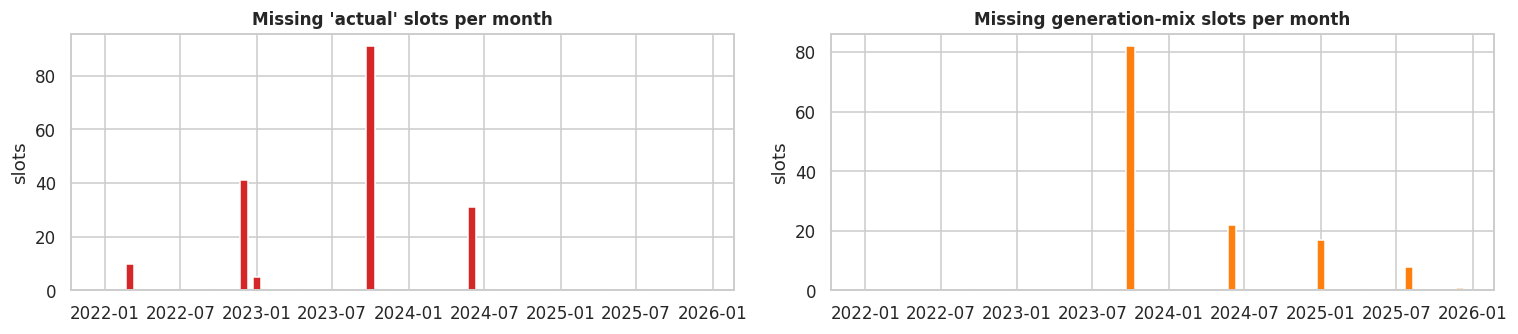

In [6]:
# FUNCTION TO FIND LONGEST CONSECUTIVE MISSING PERIODS
def gap_blocks(is_missing, top=5):
    """Longest runs of consecutive missing 30-min slots."""
    idx = is_missing[is_missing].index.to_series() # getting timestamps where data is missing
    if idx.empty:
        return pd.DataFrame() # returning an empty DataFrame if there are no missing timestamps
    run = (idx.diff() != pd.Timedelta("30min")).cumsum().to_numpy() # creating a new group whenever the gap between timestamps is not 30 minutes
    g = idx.groupby(run).agg(start="min", end="max", slots="count") # finding start, end and number of missing slots in each group
    return g.sort_values("slots", ascending=False).head(top).reset_index(drop=True) # sorting longest gaps first and returning the top results

# CHECKING MISSING VALUES
miss = pd.concat([ci.isna().sum(), gen.isna().sum()]).rename("missing").to_frame() # counting missing values in each column of both datasets
miss["pct"] = (miss["missing"] / len(FULL) * 100).round(3) # calculating missing percentage for each column
display(miss[miss["missing"] > 0]) # displaying only columns that contain missing values

# CHECKING MISSING SLOTS PER YEAR
print("Missing per year (before zero fix):")
display(pd.concat([ci.isna().groupby(ci.index.year).sum(), # counting missing values in each carbon intensity column for every year
                   gen.isna().any(axis=1).groupby(gen.index.year).sum().rename("gen_missing_slots")], axis=1)) # counting half-hour slots where at least one generation value is missing

# FINDING LONGEST MISSING PERIODS
print("Longest gaps in 'actual':");        display(gap_blocks(ci["actual"].isna())) # displaying the longest consecutive missing periods in actual carbon intensity
print("Longest gaps in generation mix:");  display(gap_blocks(gen.isna().any(axis=1))) # displaying the longest consecutive missing periods in generation data

# PLOTTING MONTHLY MISSING SLOTS
fig, ax = plt.subplots(1, 2, figsize=(14, 3.2)) # creating two plots side by side
for a, s, title, c in [(ax[0], ci["actual"].isna(), "Missing 'actual' slots per month", "tab:red"),
                       (ax[1], gen.isna().any(axis=1), "Missing generation-mix slots per month", "tab:orange")]:
    m = s.resample("MS").sum() # grouping missing slots by month and counting them
    a.bar(m.index, m.values, width=20, color=c) # plotting monthly missing-slot counts as bars
    a.set(title=title, ylabel="slots") # setting plot title and y-axis label
plt.tight_layout(); plt.show() # adjusting spacing and displaying both plots

Invalid zeros: ['2023-01-31 01:00', '2023-06-07 09:30', '2023-06-07 10:00', '2023-06-07 10:30', '2023-06-07 11:00']
'actual' missing after fix: 183 slots (0.26%)
IQR fences: [-73.5, 362.5]  ->  0 outliers flagged
Largest half-hour jumps:


,abs_change
time,
2023-01-24 11:00:00+00:00,179.0
2023-01-24 11:30:00+00:00,176.0
2023-06-07 09:00:00+00:00,68.0
2023-11-17 22:30:00+00:00,61.0
2023-10-02 21:30:00+00:00,60.0


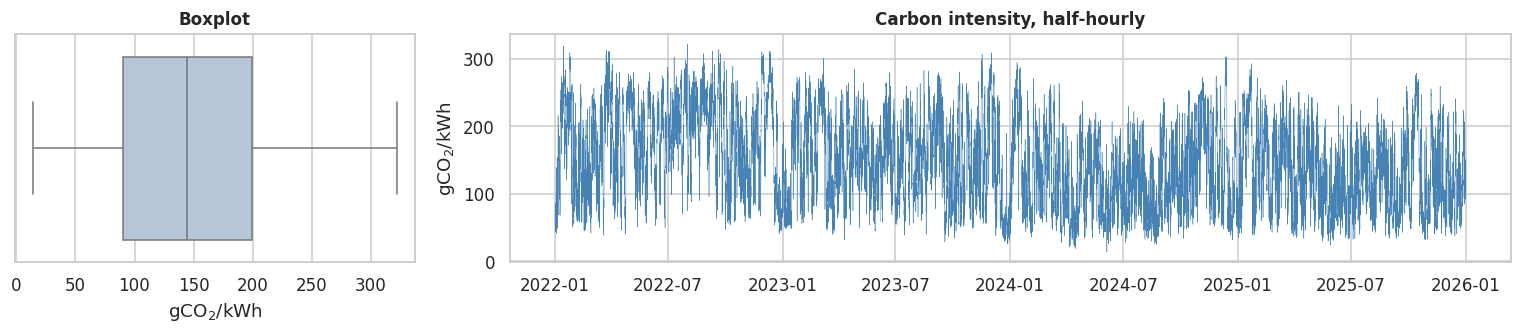

In [7]:
# IDENTIFYING AND FIXING INVALID ZERO VALUES
zero_ts = ci.index[ci["actual"] == 0] # getting timestamps where actual carbon intensity is zero
print("Invalid zeros:", [t.strftime("%Y-%m-%d %H:%M") for t in zero_ts]) # displaying timestamps of zero values in readable format
ci.loc[ci["actual"] == 0, "actual"] = np.nan # replacing zero values with NaN because they are treated as invalid
print(f"'actual' missing after fix: {ci['actual'].isna().sum()} slots ({ci['actual'].isna().mean():.2%})") # displaying total missing slots and their percentage

# OUTLIER CHECKS (FLAG ONLY, NOTHING REMOVED)
q1, q3 = ci["actual"].quantile([.25, .75]) # calculating the first and third quartiles
lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1) # calculating lower and upper IQR limits
n_out = int(((ci["actual"] < lo) | (ci["actual"] > hi)).sum()) # counting values outside the IQR limits
print(f"IQR fences: [{lo:.1f}, {hi:.1f}]  ->  {n_out} outliers flagged") # displaying the limits and number of flagged outliers
print("Largest half-hour jumps:")
display(ci["actual"].diff().abs().nlargest(5).round(1).to_frame("abs_change")) # finding the five largest absolute changes between consecutive half-hour slots

# VISUALIZING OUTLIERS AND CARBON INTENSITY
fig, ax = plt.subplots(1, 2, figsize=(14, 3.2), gridspec_kw={"width_ratios": [1, 2.5]}) # creating two plots with more space for the time-series plot
sns.boxplot(x=ci["actual"].dropna(), color="lightsteelblue", ax=ax[0]); ax[0].set(title="Boxplot", xlabel=UNIT) # showing the distribution and possible outliers in a boxplot
ax[1].plot(ci.index, ci["actual"], lw=.3, color="steelblue"); ax[1].set(title="Carbon intensity, half-hourly", ylabel=UNIT) # plotting carbon intensity values over time
plt.tight_layout(); plt.show() # adjusting spacing and displaying both plots

In [8]:
# IDENTIFYING UNREALISTIC GENERATION VALUES
night = gen.index.hour.isin([21, 22, 23, 0, 1, 2, 3]) # identifying night-time slots based on their hour
glitch = (((gen["gas"] == 0) & (gen["wind"] < 5))      # flagging rows with no gas and almost no wind
          | ((gen["solar"] > 1) & night)               # flagging solar generation during night hours
          | (gen["nuclear"] > 35))                     # flagging unusually high nuclear generation

# CHECKING FLAGGED ROWS
print("Glitch rows:", int(glitch.sum())) # counting total rows flagged as unrealistic
display(glitch.groupby(glitch.index.year).sum().to_frame("n")) # counting flagged rows separately for each year
print("Examples (target 'actual' on the same rows is normal):")
display(gen.loc[glitch].head(5).join(ci["actual"])) # displaying five flagged rows with their corresponding actual carbon intensity

# REPLACING FLAGGED GENERATION VALUES
gen.loc[glitch, FUELS] = np.nan # replacing only generation values in flagged rows; carbon intensity actual remains unchanged

Glitch rows: 34


,n
time,
2022,3
2023,4
2024,12
2025,15


Examples (target 'actual' on the same rows is normal):


,biomass,coal,imports,gas,nuclear,hydro,solar,wind,actual
time,,,,,,,,,
2022-03-10 23:00:00+00:00,0.0,2.4,34.1,0.0,61.3,2.2,0.0,0.0,75.0
2022-08-02 00:00:00+00:00,0.0,0.0,9.2,0.0,36.8,0.2,0.0,53.8,93.0
2022-10-22 03:00:00+00:00,1.7,0.0,1.6,29.7,18.0,1.4,1.3,46.3,128.0
2023-03-02 03:00:00+00:00,6.7,0.0,9.7,52.7,13.6,0.2,1.2,15.9,234.0
2023-09-21 02:00:00+00:00,3.2,1.2,7.1,13.5,27.8,1.1,1.8,44.3,75.0


### Cleaning Summary

- No duplicate timestamps were left in any dataset. After adding the 122 missing time slots, the complete dataset contains **70,128 half-hourly slots**.
- After replacing the 5 invalid zero values, `actual` has **183 missing values (0.26%)**. The target values for 2025 are complete. NESO's forecast has **165 missing values**, including 43 in 2025.
- The generation mix has **130 missing values (0.19%)**. The largest missing period is from **20 to 22 October 2023**, with around 91 slots.
- No statistical outliers were found. The IQR limits are **−73.5 to 362.5**, while the actual values range from **0 to 322**. The only invalid values found were the 5 zeros mentioned earlier.
- **34 generation rows** contained unrealistic values and were set to `NaN`. These include 3 rows in 2022, 4 in 2023, 12 in 2024 and 15 in 2025. High wind shares (above 70%) during windy nights were kept because they are possible.
- No missing values were filled. Rows with missing required data are removed when preparing the training tables in Section 6.

In [9]:
# ALIGNING HOURLY WEATHER WITH THE 30-MINUTE GRID
# Each :30 slot takes the weather value from the preceding full hour
wx_wide = wx_raw.pivot(index="time", columns="location", values=WEATHER_VARS) # converting weather data into columns for each variable and location
wx_wide.columns = [f"{var}_{loc}" for var, loc in wx_wide.columns] # combining variable and location names into single column names
wx_wide = wx_wide.reindex(FULL, method="ffill") # aligning weather with the full 30-minute grid and carrying forward the previous available value

# COMBINING ALL DATASETS
df = ci.join(gen).join(wx_wide).rename_axis("time") # joining carbon intensity, generation mix and weather into one master DataFrame

# CHECKING FINAL DATASET
assert len(df) == len(FULL) and df.index.is_monotonic_increasing # checking that all expected time slots exist and timestamps are in increasing order
assert df[wx_wide.columns].isna().sum().sum() == 0, "weather must be complete after the join" # checking that no weather values are missing after alignment

# SAVING MASTER DATASET
df.to_csv(f"{OUT}/master_clean.csv") # saving the combined and cleaned dataset as a CSV file
print("Master table:", df.shape) # displaying the number of rows and columns
display(df.head(3).T) # displaying the first three records vertically to make columns easier to inspect

Master table: (70128, 25)


time,2022-01-01 00:00:00+00:00,2022-01-01 00:30:00+00:00,2022-01-01 01:00:00+00:00
forecast_neso,74.0,70.0,70.0
actual,74.0,75.0,73.0
biomass,6.0,5.9,5.7
coal,0.0,0.0,0.0
imports,5.8,5.0,5.0
gas,11.1,11.3,10.8
nuclear,26.5,26.1,25.6
hydro,1.1,1.0,1.0
solar,0.0,0.0,0.0
wind,49.5,50.6,51.9


# 5. Preprocessing

## 5. Data Preprocessing

1. **Time alignment:** Weather data is available hourly, while the other data is in 30-minute intervals. So, each hourly weather value is carried forward to the next 30-minute slot. All timestamps remain in UTC.

2. **Daily format:** The model needs to predict 48 values for each day. So, the half-hourly carbon intensity data is converted into a matrix called `Y`, with 1461 rows (days) and 48 columns (time slots). Ridge and Random Forest use this format directly. LightGBM will use a different format where each row represents one day and one time slot.

3. **Baselines:**
   - **Yesterday:** Uses the carbon intensity value from the same time slot on the previous day.
   - **7-day average:** Takes the average of the same time slot over the previous 7 days. If even one of those days is missing, the result is set to `NaN`.

4. **Valid days:** A day is considered valid only when all 48 actual target values and both baseline values are available. The first 7 days of 2022 are always invalid because there is not enough previous data for the 7-day average. If there is a missing day, the 7-day baseline can also be missing for the following 7 days.

In [10]:
# CONVERTING HALF-HOURLY DATA INTO DAILY MATRICES
def to_day_matrix(s):
    """Half-hourly series -> (n_days x 48) matrix, one row per UTC day."""
    days = pd.DatetimeIndex(s.index[::HORIZON], name="date") # getting the first timestamp of each day to use as the row index
    return pd.DataFrame(s.to_numpy().reshape(-1, HORIZON), index=days) # reshaping values into 48 half-hourly slots per day

# CHECKING TIME GRID
assert df.index[0].hour == 0 and len(df) % HORIZON == 0 # checking that data starts at midnight and total slots can be divided into complete days

# CREATING DAILY TARGET AND BASELINE MATRICES
Y      = to_day_matrix(df["actual"]) # converting actual carbon intensity into a daily matrix of 48 values per day
NESO   = to_day_matrix(df["forecast_neso"]) # converting NESO forecast values into the same daily format
Y_yday = Y.shift(1) # using the previous day's actual values as a baseline
Y_wk7  = pd.DataFrame(np.mean([Y.shift(k).to_numpy() for k in range(1, 8)], axis=0), index=Y.index) # calculating the average of the previous seven days for each half-hour slot

# IDENTIFYING VALID TARGET DAYS
valid = Y.notna().all(axis=1) & Y_yday.notna().all(axis=1) & Y_wk7.notna().all(axis=1) # keeping days where target, previous day and seven-day average have all 48 values available
print("Target matrix Y:", Y.shape) # displaying the number of days and half-hour slots in the target matrix
display(valid.groupby(valid.index.year).agg(valid_days="sum", total_days="size")) # displaying valid and total days separately for each year

Target matrix Y: (1461, 48)


,valid_days,total_days
date,,
2022,341,365
2023,334,365
2024,357,366
2025,365,365


# 6. Feature engineering

## 6. Feature Engineering

Each forecast day is represented by one row in the feature table. The model uses information available up to 23:30 UTC on the previous day. The only exception is the target-day weather forecast, which can also be used as an input.

The following features are created:

| Group | Features | Count | Purpose |
|---|---|---|---|
| `ci_lag1d` | Carbon intensity values from all 48 slots of yesterday | 48 | Uses yesterday's daily pattern. |
| `ci_lag7d` | Carbon intensity values from the same 48 slots, 7 days ago | 48 | Uses the weekly pattern. |
| `ci_avg7d` | Average carbon intensity for each time slot over the previous 7 days | 48 | Uses the average of the last 7 days to reduce daily changes. |
| `ci_prev` | Yesterday's mean, minimum, maximum and last carbon intensity value | 4 | Gives a short summary of yesterday's carbon intensity. |
| `gen_prev` | Average share of each fuel source from yesterday | 8 | Provides information about the previous day's electricity generation. |
| `wx_prev` | Average of 4 weather variables across 3 locations for yesterday | 12 | Provides information about the previous day's weather. |
| `wx_tgt` | Target-day weather divided into four 6-hour blocks (4 variables × 3 locations × 4 blocks) | 48 | Provides weather forecast information for the day being predicted. Used for RQ3. |
| `calendar` | Weekday, month, weekend, day-of-year sin/cos and England public holiday | 6 | Helps the model learn patterns related to dates and seasons. |
### Leakage Test

A leakage test is performed to check whether future data is being used by the feature function.

For this test, a copy of the dataset is created and all data from a selected day **D** onward is replaced with `-999`. The features for day D are then calculated again and compared with the original features.

If the features remain the same, it means that the function is not using future data for those features. Target-day weather features (`wx_tgt`) are excluded from this comparison because they are allowed as forecast inputs.

In [11]:
# LOADING UK PUBLIC HOLIDAYS
try:
    import holidays
    UK_HOLIDAYS = holidays.UK(subdiv="England", years=range(2022, 2026)) # loading public holidays in England from 2022 to 2025
except ImportError:
    UK_HOLIDAYS = None
    print("WARNING: package 'holidays' missing -> is_holiday = 0   (run: pip install holidays)") # showing a warning if the package is not installed

# FEATURE GROUPS
GROUPS = ("ci_lag1d", "ci_lag7d", "ci_avg7d", "ci_prev", "gen_prev", "wx_prev", "wx_tgt")

def group_of(col):
    return next((g for g in GROUPS if col.startswith(g)), "calendar") # identifying a feature's group from its column name

# BUILDING DAILY FEATURES
def build_features(df, use_target_weather=USE_TARGET_DAY_WEATHER):
    """One row per forecast day D, built only from data up to D-1 23:30 UTC
    (plus target-day weather if use_target_weather)."""
    Y = to_day_matrix(df["actual"]) # converting actual carbon intensity into a daily matrix of 48 half-hourly values
    days, day_of = Y.index, df.index.floor("D") # getting daily dates and the day for each half-hourly timestamp

    # 1) CARBON-INTENSITY HISTORY
    lag1, lag7 = Y.shift(1), Y.shift(7) # getting carbon intensity values from one day and seven days earlier
    avg7 = pd.DataFrame(np.mean([Y.shift(k).to_numpy() for k in range(1, 8)], axis=0), index=days) # calculating the average of the previous seven days for each half-hour slot
    ci_stats = pd.DataFrame({"ci_prev_mean": lag1.mean(axis=1), "ci_prev_min": lag1.min(axis=1),
                             "ci_prev_max": lag1.max(axis=1), "ci_prev_last": lag1[HORIZON - 1]}) # calculating yesterday's mean, minimum, maximum and last carbon intensity
    parts = [lag1.add_prefix("ci_lag1d_s"), lag7.add_prefix("ci_lag7d_s"),
             avg7.add_prefix("ci_avg7d_s"), ci_stats] # storing all carbon-intensity history features

    # 2) YESTERDAY'S GENERATION MIX AND WEATHER
    wcols = [f"{v}_{loc}" for v in MODEL_WX for loc in LOCATIONS] # creating weather column names for selected variables and locations
    parts.append(df[FUELS].groupby(day_of).mean().shift(1).add_prefix("gen_prev_")) # calculating yesterday's average generation mix
    parts.append(df[wcols].groupby(day_of).mean().shift(1).add_prefix("wx_prev_")) # calculating yesterday's average weather values

    # 3) TARGET-DAY WEATHER IN 6-HOUR BLOCKS
    if use_target_weather:
        wt = df[wcols].groupby([day_of, df.index.hour // 6]).mean().unstack() # calculating average weather for each 6-hour block of the target day
        wt.columns = [f"wx_tgt_{c}_b{b}" for c, b in wt.columns] # creating column names for each weather variable, location and 6-hour block
        parts.append(wt) # adding target-day weather features

    # 4) CALENDAR FEATURES
    cal = pd.DataFrame(index=days) # creating a DataFrame for calendar features
    cal["dow"], cal["month"] = days.dayofweek, days.month # storing day of the week and month number
    cal["is_weekend"] = (days.dayofweek >= 5).astype(int) # setting weekends to 1 and weekdays to 0
    cal["doy_sin"] = np.sin(2 * np.pi * days.dayofyear / 365.25) # representing the day of the year as a sine value
    cal["doy_cos"] = np.cos(2 * np.pi * days.dayofyear / 365.25) # representing the day of the year as a cosine value
    cal["is_holiday"] = [int(d.date() in UK_HOLIDAYS) if UK_HOLIDAYS is not None else 0 for d in days] # marking UK public holidays as 1 and other days as 0
    parts.append(cal) # adding calendar features

    # COMBINING ALL FEATURES
    X = pd.concat(parts, axis=1) # combining all feature groups into one DataFrame
    X.index = days # setting the forecast dates as the index
    return X # returning the daily feature matrix

In [12]:
# BUILDING FEATURE MATRIX
X = build_features(df) # generating daily features using the master dataset

# LEAKAGE TEST: CHECKING THAT FUTURE DATA DOES NOT AFFECT FEATURES
D = pd.Timestamp("2025-06-01", tz="UTC") # selecting a forecast day to test
df_broken = df.copy() # creating a copy of the original dataset
df_broken.loc[df_broken.index >= D] = -999 # replacing all data from day D onward with an invalid value
X_broken = build_features(df_broken) # rebuilding features using the modified dataset
static = [c for c in X.columns if group_of(c) != "wx_tgt"] # selecting features that must not depend on target-day weather
assert np.allclose(X.loc[D, static].astype(float), X_broken.loc[D, static].astype(float), equal_nan=True) # checking that all selected features for day D remain unchanged
print("Leakage test PASSED: the row of day D depends only on data up to D-1 23:30 UTC")

# CREATING TRAIN, VALIDATION AND TEST SPLITS
ok   = X.notna().all(axis=1) & Y.notna().all(axis=1) # selecting days where all features and target values are available
year = pd.Series(X.index.year, index=X.index) # getting the year for each daily row
tr, va, te = ok & year.isin(TRAIN_YEARS), ok & (year == VAL_YEAR), ok & (year == TEST_YEAR) # assigning complete days to train, validation and test based on year

# LABELING EACH DAY'S SPLIT
split = pd.Series("unused", index=X.index, name="split") # marking all days as unused initially
split[tr], split[va], split[te] = "train", "val", "test" # assigning the selected days to their respective splits

# CHECKING FEATURE AND SPLIT COUNTS
print(f"X: {X.shape} | Y: {Y.shape}") # displaying the dimensions of feature and target matrices
print(f"Usable days -> train {tr.sum()} | validation {va.sum()} | test {te.sum()}") # displaying the number of usable days in each split
display(pd.Series(X.columns).map(group_of).value_counts().to_frame("n_features")) # counting features in each feature group
display(split.groupby(split.index.year).value_counts().unstack(fill_value=0)) # displaying train, validation, test and unused days for each year

# PREPARING TRAINING DATA FOR EDA
df_train = df[df.index.year.isin(TRAIN_YEARS)] # selecting training years for all train-only EDA below

# SAVING FEATURES, TARGETS AND SPLIT LABELS
X.to_csv(f"{OUT}/X_features.csv"); Y.to_csv(f"{OUT}/Y_targets.csv"); split.to_csv(f"{OUT}/day_split.csv") # saving feature matrix, target matrix and daily split labels

Leakage test PASSED: the row of day D depends only on data up to D-1 23:30 UTC
X: (1461, 222) | Y: (1461, 48)
Usable days -> train 675 | validation 357 | test 365


,n_features
ci_lag1d,48
ci_lag7d,48
ci_avg7d,48
wx_tgt,48
wx_prev,12
gen_prev,8
calendar,6
ci_prev,4


split,test,train,unused,val
date,,,,
2022,0,341,24,0
2023,0,334,31,0
2024,0,0,9,357
2025,365,0,0,0


# 7. Feature selection

## 7. Feature Selection (Training Data Only)

There are **675 training days and 222 features**. Some features are closely related to each other, especially the 48 carbon intensity values from previous days. So, feature selection is done to keep the most useful features.

Two methods are used:

- **Correlation:** Checks how strongly each feature is related to the daily average carbon intensity. It gives a basic idea of the relationship between features and the target.
- **Random Forest importance:** Shows how useful each feature is for predicting the daily average carbon intensity. It can also capture relationships that are not simply linear.

### Feature Selection Rule

Features are ranked by their Random Forest importance. The smallest group of features that reaches **95% of the total importance** is selected and saved as `SELECTED`.

In Part 2, model performance using all features (`ALL`) will be compared with performance using only the selected features (`SELECTED`). This comparison will be done on the 2024 validation data.

### Limitation

Feature importance is calculated using the daily average carbon intensity as the target. However, some features may be more useful for predicting individual 30-minute time slots. This will be checked separately in Part 2.

Constant columns: []


,|corr|,rf_importance
ci_lag1d_s47,0.853,0.2963
ci_prev_last,0.853,0.2686
ci_lag1d_s46,0.848,0.1124
wx_tgt_wind_speed_10m_london_b3,0.577,0.0477
wx_tgt_wind_speed_10m_east_coast_b2,0.671,0.0440
wx_tgt_wind_speed_10m_london_b2,0.656,0.0351
ci_lag1d_s44,0.832,0.0170
ci_lag1d_s45,0.841,0.0145
wx_tgt_wind_speed_10m_east_coast_b3,0.594,0.0096
dow,0.196,0.0081


68 of 222 features reach 95% of the RF importance


,n_selected
wx_tgt,31
ci_lag1d,16
wx_prev,8
gen_prev,7
calendar,4
ci_prev,2


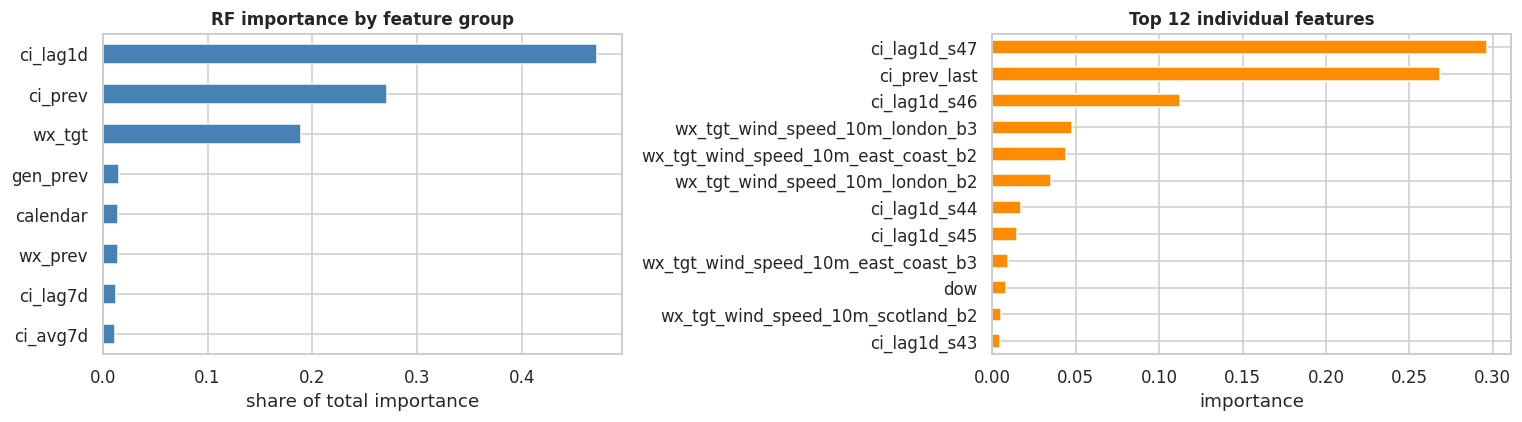

Wind-speed correlation between locations (train years):


,wind_speed_10m_london,wind_speed_10m_scotland,wind_speed_10m_east_coast
wind_speed_10m_london,1.00,0.37,0.74
wind_speed_10m_scotland,0.37,1.00,0.44
wind_speed_10m_east_coast,0.74,0.44,1.00


In [13]:
# PREPARING TRAINING DATA FOR FEATURE SELECTION
Xtr, ytr = X[tr], Y[tr].mean(axis=1) # selecting training features and calculating the daily average carbon intensity as the target
print("Constant columns:", list(Xtr.columns[Xtr.nunique() <= 1])) # identifying columns with only one unique value

# TRAINING RANDOM FOREST FOR FEATURE IMPORTANCE
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED).fit(Xtr, ytr) # training Random Forest to estimate the importance of each feature
imp = pd.Series(rf.feature_importances_, index=Xtr.columns).sort_values(ascending=False) # storing feature importance scores and sorting them from highest to lowest
corr = Xtr.corrwith(ytr) # calculating the correlation of each feature with the target

# DISPLAYING TOP FEATURES
display(pd.DataFrame({"|corr|": corr.abs().round(3), "rf_importance": imp.round(4)})
          .sort_values("rf_importance", ascending=False).head(12)) # displaying the top 12 features with their absolute correlation and Random Forest importance

# SELECTING FEATURES THAT COVER 95% OF TOTAL IMPORTANCE
SELECTED = list(imp.index[: int((imp.cumsum() < 0.95).sum()) + 1]) # selecting the highest-ranked features until cumulative importance reaches 95%
pd.Series(SELECTED).to_csv(f"{OUT}/selected_features.csv", index=False, header=["feature"]) # saving selected feature names
print(f"{len(SELECTED)} of {len(imp)} features reach 95% of the RF importance") # displaying selected features compared to total features
display(pd.Series(SELECTED).map(group_of).value_counts().to_frame("n_selected")) # counting selected features in each feature group

# VISUALIZING FEATURE IMPORTANCE
fig, ax = plt.subplots(1, 2, figsize=(14, 4)) # creating two plots side by side
imp.groupby(group_of).sum().sort_values().plot(kind="barh", ax=ax[0], color="steelblue") # combining importance scores by feature group and plotting them
ax[0].set(title="RF importance by feature group", xlabel="share of total importance") # setting the first plot title and x-axis label
imp.head(12)[::-1].plot(kind="barh", ax=ax[1], color="darkorange") # plotting the top 12 individual features in ascending order
ax[1].set(title="Top 12 individual features", xlabel="importance") # setting the second plot title and x-axis label
plt.tight_layout(); plt.show() # adjusting spacing and displaying both plots

# CHECKING WIND-SPEED CORRELATION BETWEEN LOCATIONS
print("Wind-speed correlation between locations (train years):")
display(df_train[[f"wind_speed_10m_{l}" for l in LOCATIONS]].corr().round(2)) # calculating and displaying correlations between wind speeds at different locations

### Feature Selection Results

- No constant columns were found in `X`. The `other` column had already been removed because all its values were zero.
- **Previous carbon intensity is the most important feature.** The last 30-minute value from the previous day (`ci_lag1d_s47`) has the highest correlation with daily average carbon intensity (0.85). It is also the same value as `ci_prev_last`. Along with `ci_lag1d_s46`, the top three features account for about **68% of Random Forest importance**.
- **Target-day wind speed is also useful.** Wind speed in London and East Coast, especially during the 12:00–24:00 UTC period, has a strong contribution. This is one reason for testing weather forecasts in RQ3.
- Some features contain similar information. For example, nearby carbon intensity lag values and wind speed values from different locations are strongly related. Therefore, using a smaller `SELECTED` feature set can be a useful alternative to using all 222 features.

# 8. EDA

## 8. Exploratory Data Analysis (EDA)

Most plots in this section use only the training years (2022–2023). Some plots may include other years when showing long-term changes or comparing baseline results.

The 2025 test data is not used to make any decisions in this notebook.

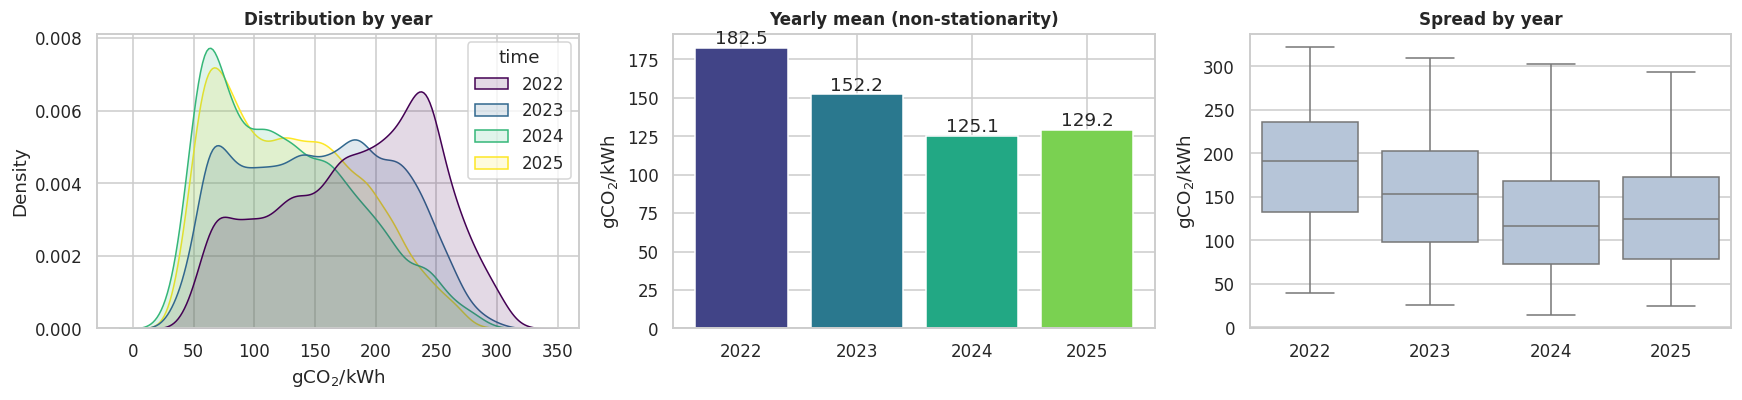

       mean   std   min    max
time                          
2022  182.5  65.1  39.0  322.0
2023  152.2  62.6  26.0  309.0
2024  125.1  59.9  14.0  303.0
2025  129.2  57.6  24.0  293.0


In [14]:
# PREPARING CARBON INTENSITY DATA BY YEAR
s  = df["actual"].dropna() # selecting actual carbon intensity values and removing missing values
yr = pd.Series(s.index.year, index=s.index) # extracting the year from each timestamp

# COMPARING DISTRIBUTIONS AND YEARLY TRENDS
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8)) # creating three plots side by side
sns.kdeplot(x=s, hue=yr, palette="viridis", common_norm=False, fill=True, alpha=.15, ax=ax[0]) # plotting carbon intensity distributions separately for each year
ax[0].set(title="Distribution by year", xlabel=UNIT) # setting the first plot title and x-axis label

ym = s.groupby(yr).mean() # calculating average carbon intensity for each year
bars = ax[1].bar(ym.index.astype(str), ym.values, color=sns.color_palette("viridis", 4)) # plotting yearly average carbon intensity as bars
ax[1].bar_label(bars, fmt="%.1f"); ax[1].set(title="Yearly mean (non-stationarity)", ylabel=UNIT) # adding values above bars and setting plot labels

sns.boxplot(x=yr, y=s, color="lightsteelblue", ax=ax[2]); ax[2].set(title="Spread by year", xlabel="", ylabel=UNIT) # comparing yearly distributions, including median, spread and possible outliers
plt.tight_layout(); plt.show() # adjusting spacing and displaying all three plots

# YEARLY SUMMARY STATISTICS
print(s.groupby(yr).agg(["mean", "std", "min", "max"]).round(1)) # displaying mean, standard deviation, minimum and maximum for each year

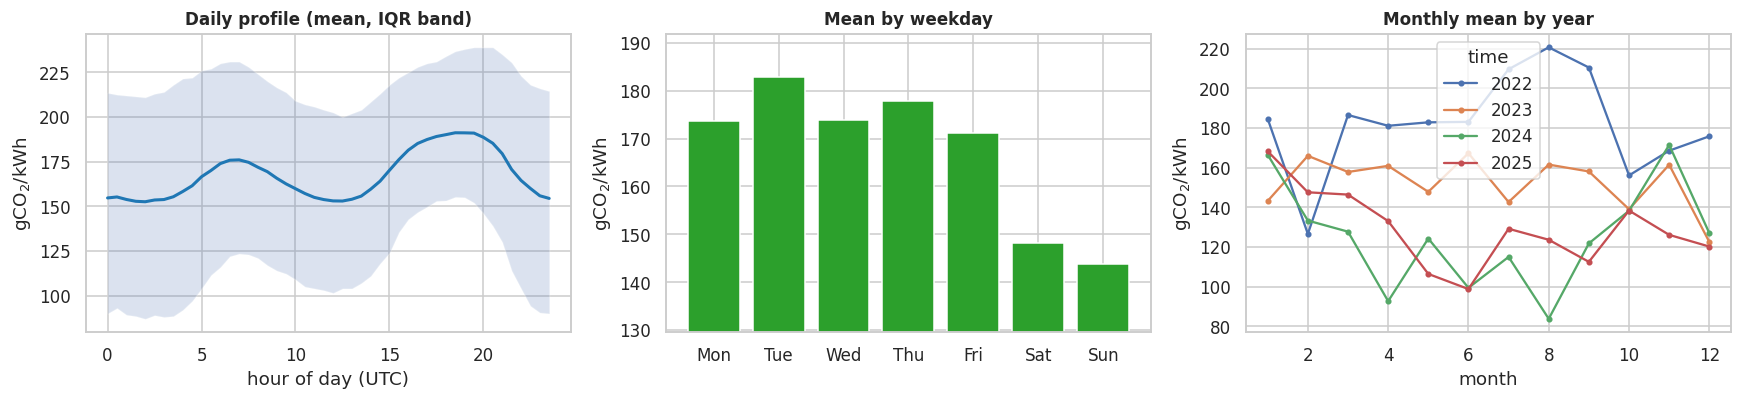

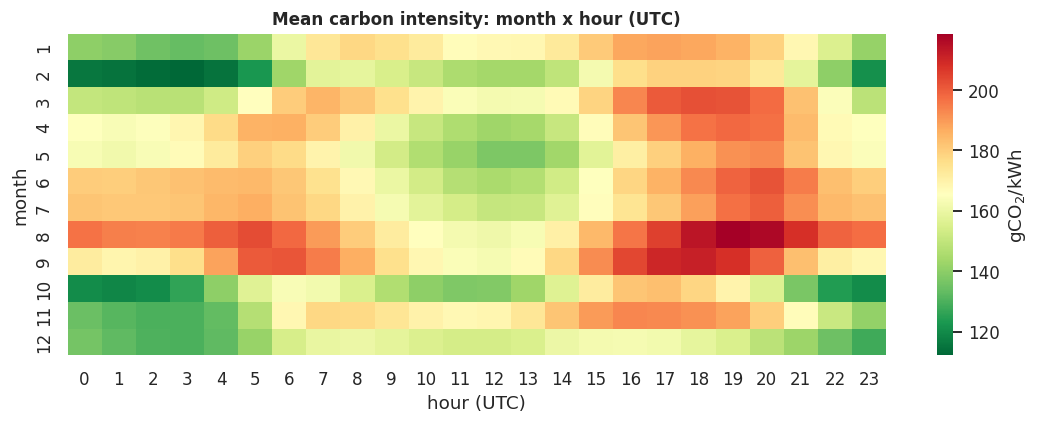

Cleanest hour (UTC): 12:00 (153.0) | dirtiest: 19:00 (191.1)
Weekday mean 175.9 vs weekend mean 146.1


In [15]:
# PREPARING TRAINING DATA FOR TEMPORAL ANALYSIS
d    = df_train # selecting training-period data for EDA
slot = d.index.hour * 2 + d.index.minute // 30 # converting each timestamp into a half-hour slot number from 0 to 47
prof = d["actual"].groupby(slot).agg(mean="mean", q25=lambda x: x.quantile(.25), q75=lambda x: x.quantile(.75)) # calculating mean and 25th and 75th percentiles for each daily slot

# PLOTTING DAILY, WEEKLY AND MONTHLY PATTERNS
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8)) # creating three plots side by side
ax[0].plot(prof.index / 2, prof["mean"], color="tab:blue", lw=2) # plotting average carbon intensity across the 24 hours
ax[0].fill_between(prof.index / 2, prof["q25"], prof["q75"], alpha=.2) # shading the range between the 25th and 75th percentiles
ax[0].set(title="Daily profile (mean, IQR band)", xlabel="hour of day (UTC)", ylabel=UNIT) # setting the first plot title and axis labels

wd = d["actual"].groupby(d.index.dayofweek).mean() # calculating average carbon intensity for each weekday
ax[1].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], wd.values, color="tab:green") # plotting average carbon intensity from Monday to Sunday
ax[1].set(title="Mean by weekday", ylabel=UNIT, ylim=(wd.min() * .9, wd.max() * 1.05)) # setting plot title, y-axis label and limits

mon = df["actual"].groupby([df.index.year, df.index.month]).mean().unstack(0) # calculating monthly averages separately for each year
mon.plot(ax=ax[2], marker="o", ms=3); ax[2].set(title="Monthly mean by year", xlabel="month", ylabel=UNIT) # plotting monthly averages to compare yearly patterns
plt.tight_layout(); plt.show() # adjusting spacing and displaying all three plots

# PLOTTING MONTH AND HOUR PATTERNS AS A HEATMAP
hm = d.pivot_table(values="actual", index=d.index.month, columns=d.index.hour, aggfunc="mean") # calculating average carbon intensity for each month and hour combination
plt.figure(figsize=(12, 3.8)) # setting the heatmap figure size
sns.heatmap(hm, cmap="RdYlGn_r", cbar_kws={"label": UNIT}); plt.title("Mean carbon intensity: month x hour (UTC)") # displaying monthly and hourly patterns using color intensity
plt.xlabel("hour (UTC)"); plt.ylabel("month"); plt.show() # setting axis labels and displaying the heatmap

# IDENTIFYING CLEANEST AND DIRTIEST HOURS
hourly = d["actual"].groupby(d.index.hour).mean() # calculating average carbon intensity for each hour of the day
print(f"Cleanest hour (UTC): {hourly.idxmin()}:00 ({hourly.min():.1f}) | dirtiest: {hourly.idxmax()}:00 ({hourly.max():.1f})") # displaying the hours with the lowest and highest average carbon intensity
print(f"Weekday mean {wd[:5].mean():.1f} vs weekend mean {wd[5:].mean():.1f}") # comparing average carbon intensity on weekdays and weekends

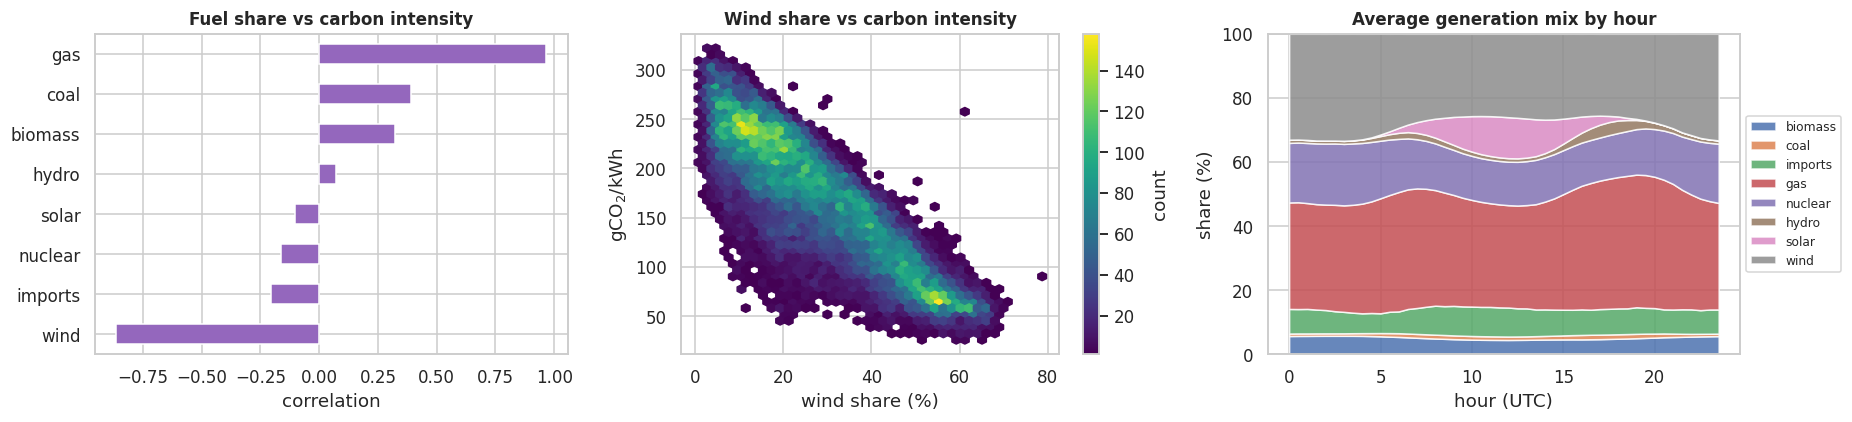

In [16]:
# PREPARING GENERATION MIX DATA
d = df_train # selecting training-period data for EDA
mixh = d[FUELS].groupby(d.index.hour * 2 + d.index.minute // 30).mean() # calculating average share of each fuel for every half-hour slot
dd = d[["wind", "actual"]].dropna() # selecting wind share and actual carbon intensity, removing missing values

# COMPARING FUEL MIX AND CARBON INTENSITY
fig, ax = plt.subplots(1, 3, figsize=(17, 4)) # creating three plots side by side
d[FUELS + ["actual"]].corr()["actual"].drop("actual").sort_values().plot(kind="barh", ax=ax[0], color="tab:purple") # calculating and plotting the correlation of each fuel share with carbon intensity
ax[0].set(title="Fuel share vs carbon intensity", xlabel="correlation") # setting the first plot title and x-axis label

# WIND SHARE VS CARBON INTENSITY
hb = ax[1].hexbin(dd["wind"], dd["actual"], gridsize=40, cmap="viridis", mincnt=1) # showing the relationship between wind share and carbon intensity using hexagonal bins
plt.colorbar(hb, ax=ax[1], label="count"); ax[1].set(title="Wind share vs carbon intensity", xlabel="wind share (%)", ylabel=UNIT) # adding a color scale to show the number of observations in each bin and setting plot labels

# AVERAGE GENERATION MIX BY HOUR
ax[2].stackplot(mixh.index / 2, mixh.T.to_numpy(), labels=FUELS, alpha=.85) # plotting average contribution of each fuel across the 24 hours as a stacked area chart
ax[2].set(title="Average generation mix by hour", xlabel="hour (UTC)", ylabel="share (%)", ylim=(0, 100)) # setting plot title, axis labels and percentage range
ax[2].legend(loc="center left", bbox_to_anchor=(1, .5), fontsize=8) # placing the fuel legend outside the plot
plt.tight_layout(); plt.show() # adjusting spacing and displaying all three plots

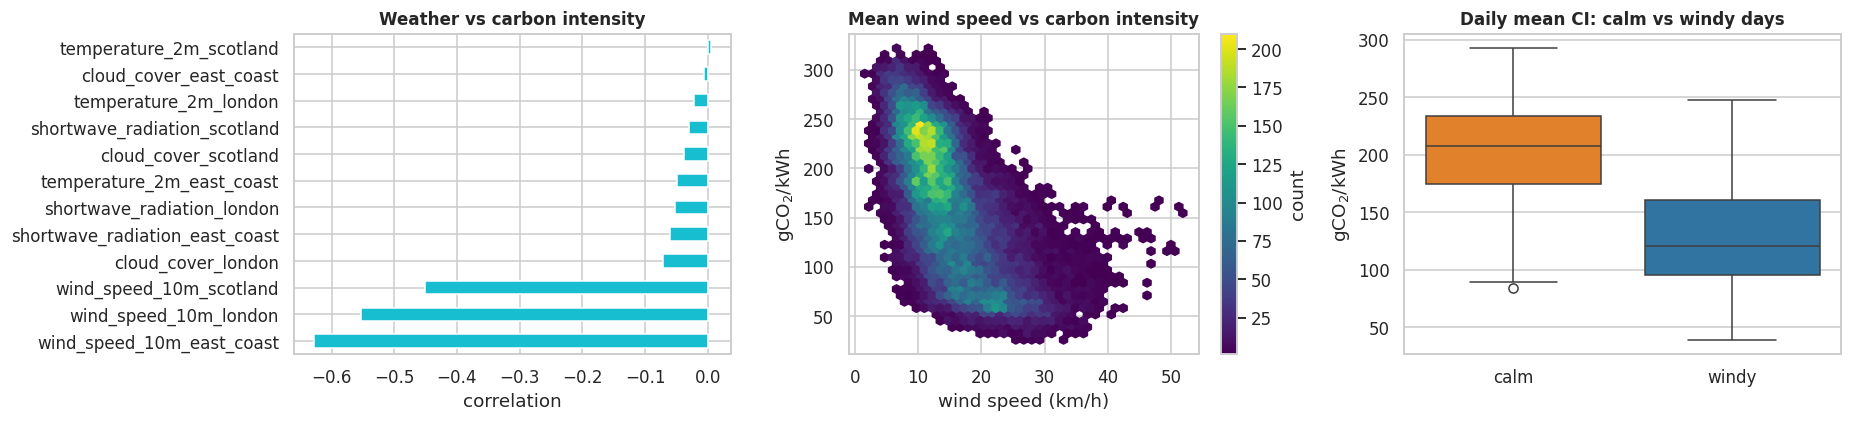

,mean,std,count
calm,203.4,41.5,338
windy,129.3,46.3,337


In [17]:
# PREPARING WEATHER DATA
d = df_train # selecting training-period data for EDA
wx_cols  = [f"{v}_{loc}" for v in MODEL_WX for loc in LOCATIONS] # creating column names for selected weather variables across all locations
wind_avg = d[[f"wind_speed_10m_{l}" for l in LOCATIONS]].mean(axis=1) # calculating average wind speed across the three locations for each half-hour slot

# CLASSIFYING DAYS AS CALM OR WINDY
day_wind = df[[f"wind_speed_10m_{l}" for l in LOCATIONS]].mean(axis=1).groupby(df.index.floor("D")).mean() # calculating daily average wind speed across all three locations
day_wind = pd.Series(day_wind.to_numpy(), index=X.index) # aligning daily wind values with the feature matrix dates
regime   = pd.Series(np.where(day_wind > day_wind[tr].median(), "windy", "calm"), index=X.index) # classifying days as windy or calm using the training-period median wind speed
day_ci   = Y[tr].mean(axis=1) # calculating daily average carbon intensity for training days

# COMPARING WEATHER AND CARBON INTENSITY
fig, ax = plt.subplots(1, 3, figsize=(17, 4)) # creating three plots side by side
d[wx_cols].corrwith(d["actual"]).sort_values().plot(kind="barh", ax=ax[0], color="tab:cyan") # calculating and plotting correlation of each weather feature with carbon intensity
ax[0].set(title="Weather vs carbon intensity", xlabel="correlation") # setting the first plot title and x-axis label

# WIND SPEED VS CARBON INTENSITY
tmp = pd.concat([wind_avg.rename("w"), d["actual"]], axis=1).dropna() # combining average wind speed and carbon intensity, then removing missing values
hb = ax[1].hexbin(tmp["w"], tmp["actual"], gridsize=40, cmap="viridis", mincnt=1) # showing the relationship between wind speed and carbon intensity using hexagonal bins
plt.colorbar(hb, ax=ax[1], label="count"); ax[1].set(title="Mean wind speed vs carbon intensity", xlabel="wind speed (km/h)", ylabel=UNIT) # adding a color scale for observation counts and setting plot labels

# COMPARING CARBON INTENSITY ON CALM AND WINDY DAYS
sns.boxplot(x=regime[tr], y=day_ci, order=["calm", "windy"], palette=["tab:orange", "tab:blue"], ax=ax[2]) # comparing daily carbon intensity distributions for calm and windy training days
ax[2].set(title="Daily mean CI: calm vs windy days", xlabel="", ylabel=UNIT) # setting the third plot title and axis labels
plt.tight_layout(); plt.show() # adjusting spacing and displaying all three plots

# SUMMARY STATISTICS FOR EACH WIND REGIME
display(day_ci.groupby(regime[tr]).agg(["mean", "std", "count"]).round(1)) # displaying mean, standard deviation and number of days for each regime

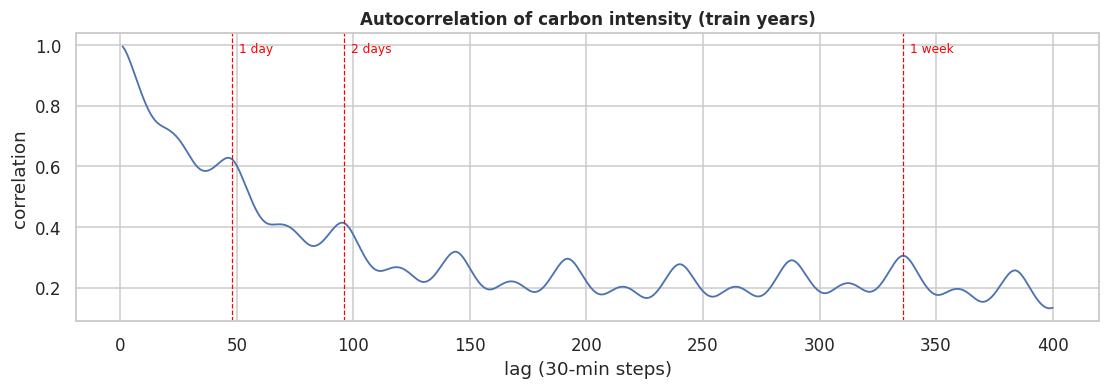

{1: np.float64(0.994), 48: np.float64(0.623), 96: np.float64(0.413), 336: np.float64(0.306)}


In [18]:
# CALCULATING AUTOCORRELATION
s   = df_train["actual"] # selecting actual carbon intensity values from training years
acf = pd.Series([s.autocorr(l) for l in range(1, 401)], index=range(1, 401)) # calculating correlation between the series and its shifted values for lags 1 to 400

# PLOTTING AUTOCORRELATION
plt.figure(figsize=(12, 3.4)) # setting the plot size
plt.plot(acf.index, acf.values, lw=1.2) # plotting correlation values against their corresponding time lags
for lag, lab in [(48, "1 day"), (96, "2 days"), (336, "1 week")]:
    plt.axvline(lag, ls="--", c="red", lw=.8) # marking important time lags with vertical dashed lines
    plt.text(lag + 3, acf.max() * .98, lab, color="red", fontsize=8) # labeling each marked lag on the plot
plt.title("Autocorrelation of carbon intensity (train years)"); plt.xlabel("lag (30-min steps)"); plt.ylabel("correlation") # setting plot title and axis labels
plt.show() # displaying the autocorrelation plot

# DISPLAYING SELECTED LAG CORRELATIONS
print({lag: round(acf[lag], 3) for lag in (1, 48, 96, 336)}) # displaying correlations at 1-step, 1-day, 2-day and 1-week lags

,days,Yesterday,7-day avg,NESO
2022,341.0,43.4,48.1,9.6
2023,334.0,42.4,45.5,9.7
2024,357.0,40.6,42.3,10.0
2025,361.0,38.9,42.1,9.2


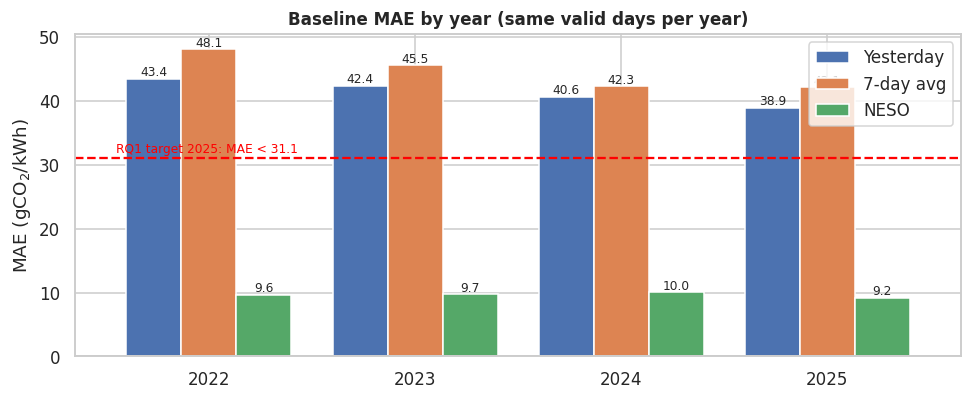

RQ1 target (20% below the better simple baseline in 2025): MAE < 31.1


In [19]:
# DEFINING MAE
mae = lambda a, b: float(np.abs(a.to_numpy() - b.to_numpy()).mean()) # calculating mean absolute error between actual and predicted values
common = ok & NESO.notna().all(axis=1) # selecting the same valid days for all baseline methods

# CALCULATING BASELINE MAE BY YEAR
rows = {}
for yv in range(2022, 2026):
    m = common & (X.index.year == yv) # selecting valid days for the current year
    rows[yv] = {"days": int(m.sum()), "Yesterday": mae(Y[m], Y_yday[m]),
                "7-day avg": mae(Y[m], Y_wk7[m]), "NESO": mae(Y[m], NESO[m])} # storing valid day count and MAE for each baseline
bl = pd.DataFrame(rows).T # converting yearly results into a DataFrame
display(bl.round(1)) # displaying baseline MAE values rounded to one decimal place

# SETTING THE 2025 PERFORMANCE TARGET
rq1_target = 0.8 * min(bl.loc[2025, "Yesterday"], bl.loc[2025, "7-day avg"]) # setting the target 20% below the better simple baseline MAE in 2025

# PLOTTING BASELINE MAE BY YEAR
ax = bl[["Yesterday", "7-day avg", "NESO"]].plot(kind="bar", figsize=(9, 3.8), width=.8, rot=0) # comparing MAE of all three baselines across years
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f", fontsize=8) # displaying MAE values on top of each bar
ax.axhline(rq1_target, ls="--", c="red"); ax.text(-0.45, rq1_target + .8, f"RQ1 target 2025: MAE < {rq1_target:.1f}", color="red", fontsize=8) # marking and labeling the 2025 performance target
ax.set(title="Baseline MAE by year (same valid days per year)", ylabel=f"MAE ({UNIT})", xlabel="") # setting plot title and axis labels
plt.tight_layout(); plt.show() # adjusting spacing and displaying the plot

# DISPLAYING THE PERFORMANCE TARGET
print(f"RQ1 target (20% below the better simple baseline in 2025): MAE < {rq1_target:.1f}") # printing the required MAE target

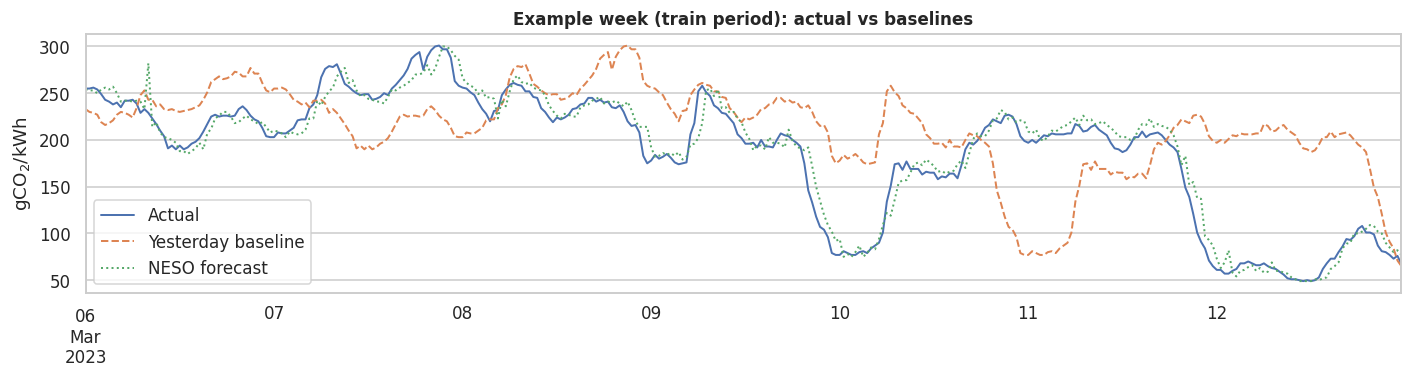

In [20]:
# SELECTING AN EXAMPLE WEEK
wk = slice("2023-03-06", "2023-03-12") # selecting one week from the training period

# PREPARING DATA FOR COMPARISON
view = pd.DataFrame({"Actual": df["actual"], "Yesterday baseline": df["actual"].shift(HORIZON),
                     "NESO forecast": df["forecast_neso"]}).loc[wk] # combining actual carbon intensity, yesterday baseline and NESO forecast for the selected week

# PLOTTING ACTUAL AND BASELINE VALUES
ax = view.plot(figsize=(13, 3.6), lw=1.3, style=["-", "--", ":"]) # plotting all three series with different line styles
ax.set(title="Example week (train period): actual vs baselines", ylabel=UNIT, xlabel="") # setting plot title and axis labels
plt.tight_layout(); plt.show() # adjusting spacing and displaying the plot

# 9. Observations and conclusion

## 9. Main Findings from EDA

1. **Data quality:** The raw datasets contain 70,006 carbon intensity records, 69,998 generation records and 105,192 weather records. The complete half-hourly time grid contains 70,128 slots. After replacing the 5 invalid zero values, 183 carbon intensity values are missing (0.26%). The 2025 target data is complete. The generation mix has 130 missing slots (0.19%), with its largest gap containing 82 consecutive slots from 20 to 22 October 2023. No missing values were filled.

2. **Carbon intensity changes over the years:** The yearly average decreases from **182.5 in 2022 to 152.1 in 2023, 125.1 in 2024 and 129.2 in 2025**. This means the average carbon intensity in 2025 is about 29% lower than in 2022. Because of this change, the model needs to be tested on later years as well. That is why 2024 is used for validation and 2025 for testing.

3. **Daily and seasonal patterns:** Carbon intensity changes throughout the day and across different months (Figures 8.2). The cleanest hour is 12:00 UTC, with an average carbon intensity of 153.0, while the dirtiest hour is 19:00 UTC, with an average of 191.1. The weekday average is 175.9, compared to 146.1 on weekends. The autocorrelation values are 0.994 at 1 step, 0.623 at 48 steps (1 day), 0.413 at 96 steps (2 days) and 0.306 at 336 steps (1 week). These patterns support the use of previous-day and previous-week features.

4. **Effect of wind and generation mix:** Wind share has a clear negative relationship with carbon intensity (Cell 26). On windy days, the average carbon intensity is **129.3**, compared to **203.4 on calm days**. These results are from the training years, with 337 windy days and 338 calm days. This difference makes it useful to check model performance separately on windy and calm days in Part 2.

5. **Previous carbon intensity is the strongest feature:** Yesterday's last 30-minute carbon intensity value has a correlation of 0.85 with the daily average. The top three features account for about 68% of Random Forest importance. After previous carbon intensity, target-day wind speed, mainly in London and East Coast during afternoon and evening, is also useful. RQ3 will check the effect of using proper weather forecasts.

6. **Baseline comparison:** Yesterday's baseline MAE decreases from 43.4 in 2022 to 42.4 in 2023, 40.6 in 2024 and 38.9 in 2025. The 7-day average baseline has a higher MAE in every year: 48.1, 45.5, 42.3 and 42.1. NESO's forecast has a much lower MAE, between 9.2 and 10.0, but it is not a direct comparison because its forecast lead time is different. The 2025 target is **MAE below 31.1**. The 2025 baseline comparison uses 361 common valid days because NESO forecast data is not complete for all 365 test days.

7. **High wind values were kept:** Wind shares above 70% were not removed because they can occur during windy conditions. Only 34 rows with unrealistic generation values were set to `NaN`.

8. **What these results mean for modelling:**
   - There are 222 features but only 675 training days, so feature selection and regularisation are important.
   - Target-day weather can be switched on or off using a setting. This will help compare different weather inputs in RQ3.
   - All models and baselines will be compared using the same valid days.

## 10. Conclusion and Next Steps (Part 2)

In Part 1, the data was collected, cleaned and prepared for modelling. The feature matrix `X` contains **1,461 days and 222 features**, while the target matrix `Y` contains **1,461 days and 48 values per day**.

The data was divided into 675 training days, 357 validation days and 365 test days. A smaller feature set was also selected using 95% cumulative Random Forest importance, and the baseline results were calculated.

In Part 2, Ridge, Random Forest and LightGBM will be trained and compared. The remaining research questions will also be checked, including prediction error at each time slot, the effect of weather forecasts and the quality of the recommended 3-hour window.

Finally, a `predict(date)` function will be prepared to generate predictions for a selected date.